### This program try to tone a program which leverage the solar library and output solar angle by input position and date read from solar_data.csv

In [10]:
import sys
print("Python version:", sys.version)

Python version: 3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]


In [11]:
import sys
import numpy as np
import pvlib
import pandas as pd
import matplotlib.pyplot as plt


print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("pvlib version:", pvlib.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

Python version: 3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]
NumPy version: 2.0.1
pvlib version: 0.11.2
Pandas version: 2.2.3
Matplotlib version: 3.9.2


In [12]:

# read the site_params.csv file
solar_data = pd.read_csv('../../../Dataset/RealData/solar_data.csv')
site_params = pd.read_csv('../../../Dataset/RealData/site_params.csv')
print(solar_data)
print(site_params)

       site_id        timestamp_utc  solar_gen_kwh
0            1  2019-03-01 00:30:00            0.0
1            1  2019-03-01 01:00:00            0.0
2            1  2019-03-01 01:30:00            0.0
3            1  2019-03-01 02:00:00            0.0
4            1  2019-03-01 02:30:00            0.0
...        ...                  ...            ...
70123        4  2022-10-31 21:30:00            0.0
70124        4  2022-10-31 22:00:00            0.0
70125        4  2022-10-31 22:30:00            0.0
70126        4  2022-10-31 23:00:00            0.0
70127        4  2022-10-31 23:30:00            0.0

[70128 rows x 3 columns]
   site_id  latitude  longitude  pv_dc_kwp  pv_array_tilt  \
0        1      53.5       -2.7       3.18             33   
1        2      53.5       -2.6       3.98             25   
2        3      51.2       -0.3       5.29              5   
3        4      51.3       -2.2       3.51             31   

   pv_array_a_orientation  
0                     200  


Save Site parameters as class for better manipulating

In [13]:
# define a class to save SiteParameters
class SiteParameters:
    def __init__(self, site_id, latitude, longitude, pv_dc_kwp, pv_array_tilt, pv_array_a_orientation):
        self.site_id = site_id
        self.latitude = latitude
        self.longitude = longitude
        self.pv_dc_kwp = pv_dc_kwp
        self.pv_array_tilt = pv_array_tilt
        self.pv_array_a_orientation = pv_array_a_orientation
        
# Define four different sites from the site_params DataFrame
site1 = SiteParameters(int(site_params.iloc[0]['site_id']), site_params.iloc[0]['latitude'], site_params.iloc[0]['longitude'], site_params.iloc[0]['pv_dc_kwp'], site_params.iloc[0]['pv_array_tilt'], site_params.iloc[0]['pv_array_a_orientation'])
site2 = SiteParameters(site_params.iloc[1]['site_id'], site_params.iloc[1]['latitude'], site_params.iloc[1]['longitude'], site_params.iloc[1]['pv_dc_kwp'], site_params.iloc[1]['pv_array_tilt'], site_params.iloc[1]['pv_array_a_orientation'])
site3 = SiteParameters(site_params.iloc[2]['site_id'], site_params.iloc[2]['latitude'], site_params.iloc[2]['longitude'], site_params.iloc[2]['pv_dc_kwp'], site_params.iloc[2]['pv_array_tilt'], site_params.iloc[2]['pv_array_a_orientation'])
site4 = SiteParameters(site_params.iloc[3]['site_id'], site_params.iloc[3]['latitude'], site_params.iloc[3]['longitude'], site_params.iloc[3]['pv_dc_kwp'], site_params.iloc[3]['pv_array_tilt'], site_params.iloc[3]['pv_array_a_orientation'])

In [14]:
int(site_params.iloc[0]['site_id'])

1

Compute Solar angles base on the date provided by the company

In [15]:
times = pd.to_datetime(solar_data['timestamp_utc']).dt.tz_localize('UTC').unique()
times = times[(times >= '2019-03-01 00:30:00') & (times <= '2020-03-01 00:30:00')]

solar_position = pvlib.solarposition.get_solarposition(times, site1.latitude, site1.longitude, 0)
print(solar_position[['apparent_zenith', 'azimuth']])

                           apparent_zenith     azimuth
2019-03-01 00:30:00+00:00       134.252878    2.326548
2019-03-01 01:00:00+00:00       133.664075   12.625207
2019-03-01 01:30:00+00:00       132.304757   22.619958
2019-03-01 02:00:00+00:00       130.244899   32.128027
2019-03-01 02:30:00+00:00       127.577603   41.049271
...                                    ...         ...
2020-02-29 22:00:00+00:00       125.705348  314.441018
2020-02-29 22:30:00+00:00       128.641159  323.020895
2020-02-29 23:00:00+00:00       131.024285  332.200035
2020-02-29 23:30:00+00:00       132.756364  341.921343
2020-03-01 00:00:00+00:00       133.754028  352.046508

[17568 rows x 2 columns]


Plotting zenith angle and azimuth angle for a given time period

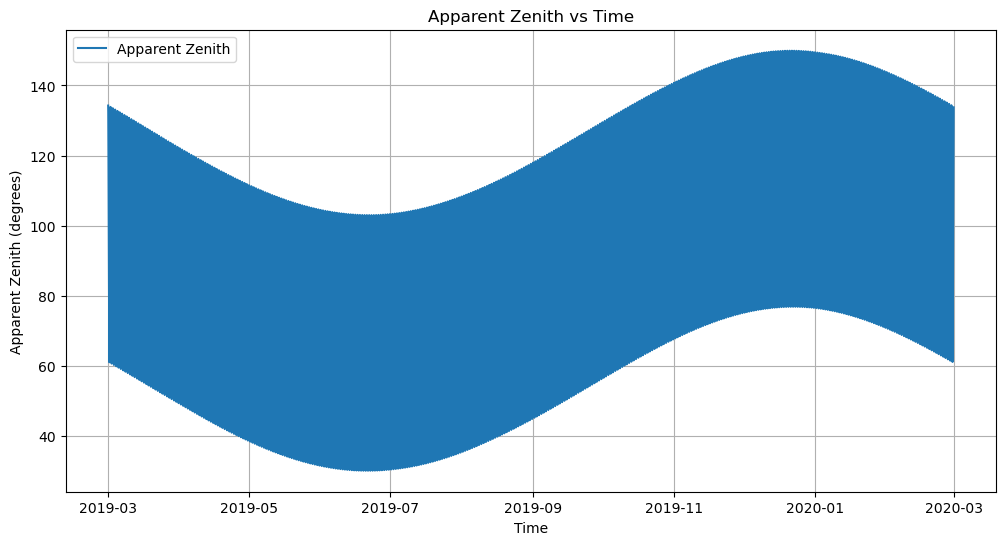

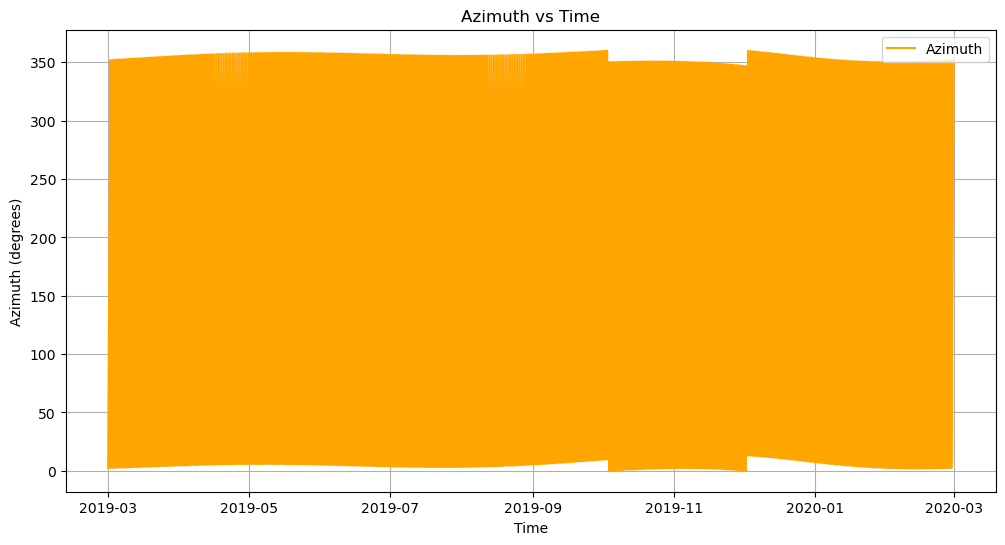

In [16]:
# Plot apparent_zenith versus time
plt.figure(figsize=(12, 6))
plt.plot(solar_position.index, solar_position['apparent_zenith'], label='Apparent Zenith')
plt.xlabel('Time')
plt.ylabel('Apparent Zenith (degrees)')
plt.title('Apparent Zenith vs Time')
plt.legend()
plt.grid(True)
plt.show()

# Plot azimuth versus time
plt.figure(figsize=(12, 6))
plt.plot(solar_position.index, solar_position['azimuth'], label='Azimuth', color='orange')
plt.xlabel('Time')
plt.ylabel('Azimuth (degrees)')
plt.title('Azimuth vs Time')
plt.legend()
plt.grid(True)
plt.show()

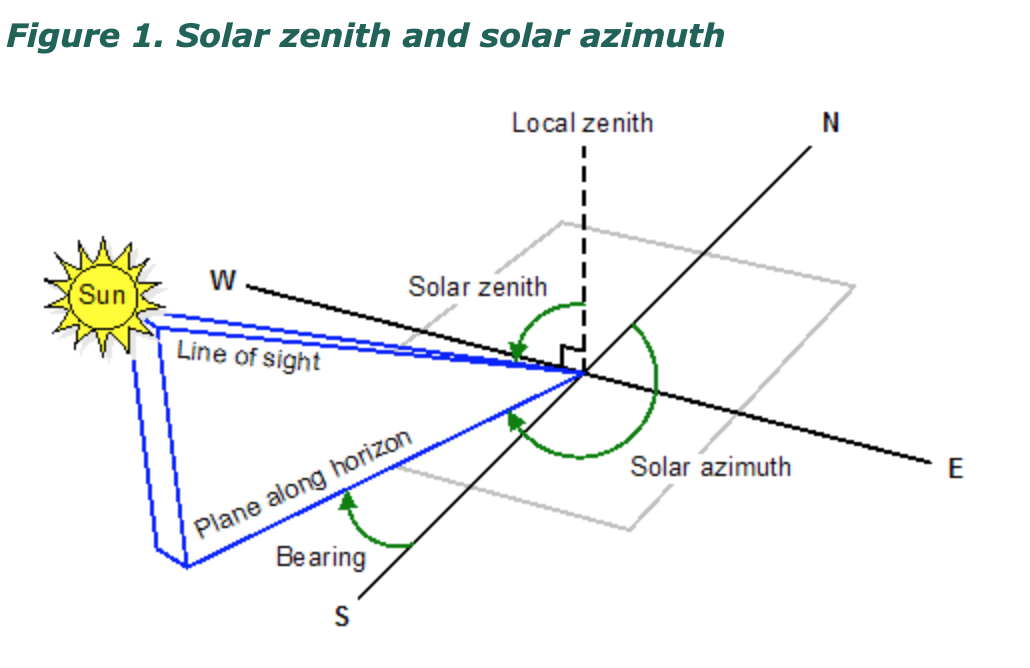

Compare the effect of Height to the solar angles.

Conclusion: almost no effect

                           apparent_zenith     azimuth
2019-03-01 00:30:00+00:00       134.252881    2.326548
2019-03-01 01:00:00+00:00       133.664077   12.625207
2019-03-01 01:30:00+00:00       132.304759   22.619958
2019-03-01 02:00:00+00:00       130.244902   32.128027
2019-03-01 02:30:00+00:00       127.577606   41.049271
...                                    ...         ...
2019-03-02 22:30:00+00:00       128.222424  323.314157
2019-03-02 23:00:00+00:00       130.587436  332.455266
2019-03-02 23:30:00+00:00       132.302963  342.125503
2019-03-03 00:00:00+00:00       133.287439  352.188156
2019-03-03 00:30:00+00:00       133.488879    2.435088

[97 rows x 2 columns]
                           apparent_zenith     azimuth
2019-03-01 00:30:00+00:00       134.252878    2.326548
2019-03-01 01:00:00+00:00       133.664075   12.625207
2019-03-01 01:30:00+00:00       132.304757   22.619958
2019-03-01 02:00:00+00:00       130.244899   32.128027
2019-03-01 02:30:00+00:00       127.577603

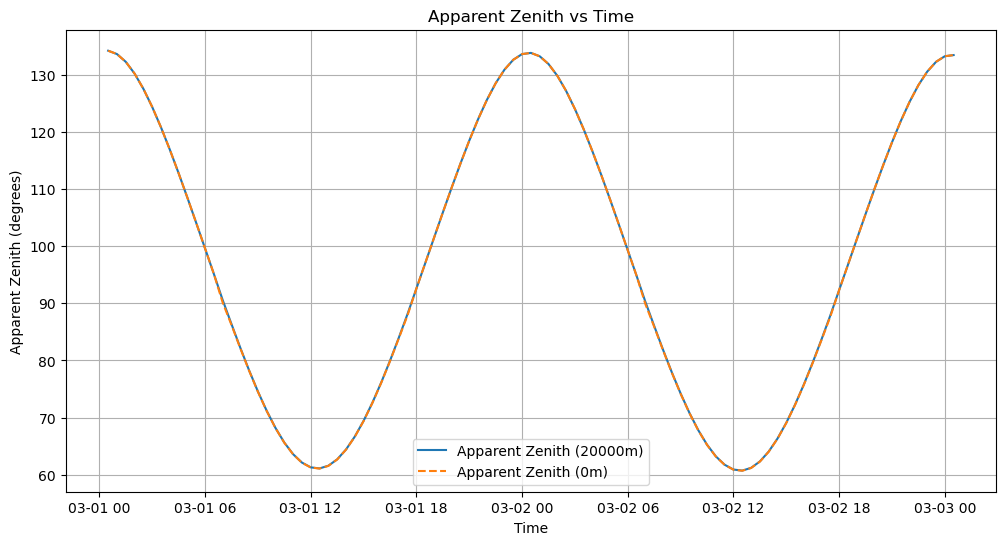

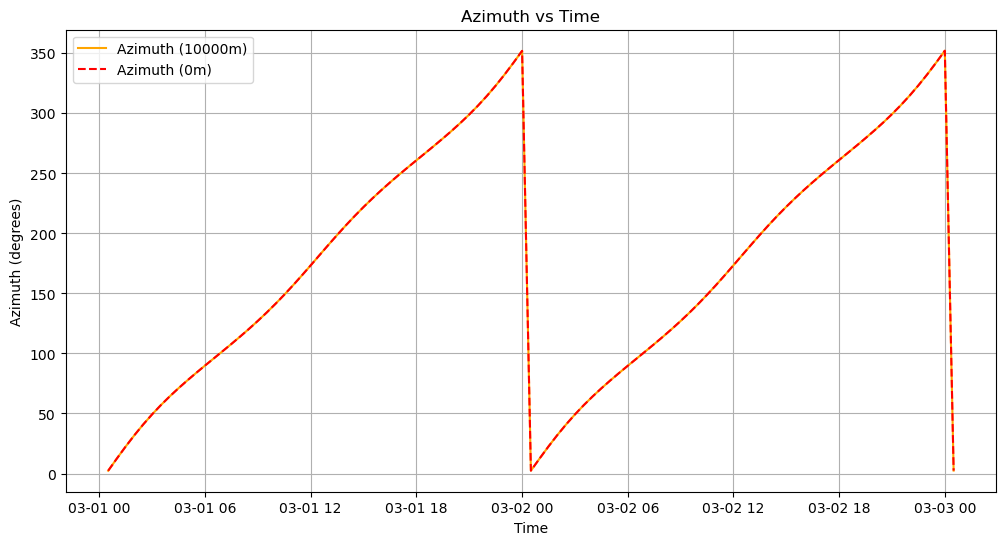

In [17]:
times = pd.to_datetime(solar_data['timestamp_utc']).dt.tz_localize('UTC').unique()
times = times[(times >= '2019-03-01 00:30:00') & (times <= '2019-03-03 00:30:00')]

solar_position1 = pvlib.solarposition.get_solarposition(times, site1.latitude, site1.longitude, 10000)
solar_position2 = pvlib.solarposition.get_solarposition(times, site1.latitude, site1.longitude, 0)

print(solar_position1[['apparent_zenith', 'azimuth']])
print(solar_position2[['apparent_zenith', 'azimuth']])
# Plot apparent_zenith versus time for both positions
plt.figure(figsize=(12, 6))
plt.plot(solar_position1.index, solar_position1['apparent_zenith'], label='Apparent Zenith (20000m)')
plt.plot(solar_position2.index, solar_position2['apparent_zenith'], label='Apparent Zenith (0m)', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Apparent Zenith (degrees)')
plt.title('Apparent Zenith vs Time')
plt.legend()
plt.grid(True)
plt.show()

# Plot azimuth versus time for both positions
plt.figure(figsize=(12, 6))
plt.plot(solar_position1.index, solar_position1['azimuth'], label='Azimuth (10000m)', color='orange')
plt.plot(solar_position2.index, solar_position2['azimuth'], label='Azimuth (0m)', color='red', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Azimuth (degrees)')
plt.title('Azimuth vs Time')
plt.legend()
plt.grid(True)
plt.show()

The height effect is really tiny and neglectable to the Solar's angle. Gound horizon level is more important.

In [19]:
# Read the solar_data again
solar_data = pd.read_csv('../../../Dataset/RealData/solar_data.csv')
# Initialize columns for solar angles
solar_data['apparent_zenith'] = np.nan
solar_data['azimuth'] = np.nan

# Compute solar angles and add to solar_data
for site in [site1, site2, site3, site4]:
    site_times = pd.to_datetime(solar_data[solar_data['site_id'] == site.site_id]['timestamp_utc']).dt.tz_localize('UTC').unique()
    solar_position = pvlib.solarposition.get_solarposition(site_times, site.latitude, site.longitude, 0)
    solar_data.loc[solar_data['site_id'] == site.site_id, 'apparent_zenith'] = solar_position['apparent_zenith'].values
    solar_data.loc[solar_data['site_id'] == site.site_id, 'azimuth'] = solar_position['azimuth'].values

# for i, angles in enumerate(solar_angles):
#     print(f"Site {i+1} Solar Angles:")
#     print(angles)
solar_data

,site_id,timestamp_utc,solar_gen_kwh,apparent_zenith,azimuth
0,1,2019-03-01 00:30:00,0.0,134.252878,2.326548
1,1,2019-03-01 01:00:00,0.0,133.664075,12.625207
2,1,2019-03-01 01:30:00,0.0,132.304757,22.619958
3,1,2019-03-01 02:00:00,0.0,130.244899,32.128027
4,1,2019-03-01 02:30:00,0.0,127.577603,41.049271
...,...,...,...,...,...
70123,4,2022-10-31 21:30:00,0.0,133.282747,309.213543
70124,4,2022-10-31 22:00:00,0.0,136.676239,318.307501
70125,4,2022-10-31 22:30:00,0.0,139.484606,328.350624
70126,4,2022-10-31 23:00:00,0.0,141.561011,339.316163


In [20]:
# Merge site parameters into the solar_data DataFrame
solar_data = solar_data.merge(site_params, on='site_id', how='left')
print(solar_data)
# Add site parameters into new columns for each site
for site in [site1, site2, site3, site4]:
    solar_data.loc[solar_data['site_id'] == site.site_id, 'latitude'] = site.latitude
    solar_data.loc[solar_data['site_id'] == site.site_id, 'longitude'] = site.longitude
    solar_data.loc[solar_data['site_id'] == site.site_id, 'pv_dc_kwp'] = site.pv_dc_kwp
    solar_data.loc[solar_data['site_id'] == site.site_id, 'pv_array_tilt'] = site.pv_array_tilt
    solar_data.loc[solar_data['site_id'] == site.site_id, 'pv_array_a_orientation'] = site.pv_array_a_orientation

print(solar_data)

       site_id        timestamp_utc  solar_gen_kwh  apparent_zenith  \
0            1  2019-03-01 00:30:00            0.0       134.252878   
1            1  2019-03-01 01:00:00            0.0       133.664075   
2            1  2019-03-01 01:30:00            0.0       132.304757   
3            1  2019-03-01 02:00:00            0.0       130.244899   
4            1  2019-03-01 02:30:00            0.0       127.577603   
...        ...                  ...            ...              ...   
70123        4  2022-10-31 21:30:00            0.0       133.282747   
70124        4  2022-10-31 22:00:00            0.0       136.676239   
70125        4  2022-10-31 22:30:00            0.0       139.484606   
70126        4  2022-10-31 23:00:00            0.0       141.561011   
70127        4  2022-10-31 23:30:00            0.0       142.770038   

          azimuth  latitude  longitude  pv_dc_kwp  pv_array_tilt  \
0        2.326548      53.5       -2.7       3.18             33   
1       12.

In [21]:
# save_path = '../../Dataset/solar_data_angles.csv'
save_path = './validation_Data.csv'
solar_data.to_csv(save_path, index=False)

In [12]:
# solar_data.describe()
# solar_data.isna().sum()

In [ ]:
# Function to plot azimuth angle on a daily timeline with different colors for different times of the year
def plot_yearly_azimuth_on_daily_timeline(solar_data, site_id):
    site_data = solar_data[solar_data['site_id'] == site_id]
    site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
    site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60
    site_data['month'] = pd.to_datetime(site_data['timestamp_utc']).dt.month

    plt.figure(figsize=(12, 8))
    colors = plt.cm.jet(np.linspace(0, 1, 12))  # 12 colors for 12 months
    for month in range(1, 13):
        month_data = site_data[site_data['month'] == month]
        plt.plot(month_data['hour'], month_data['azimuth'], '.', alpha=0.5, label=f'Month {month}', color=colors[month-1])
    
    plt.xlabel('Time of Day (hours)')
    plt.ylabel('Azimuth (degrees)')
    plt.title(f'Yearly Azimuth Angle Overlapping on Daily Timeline for Site {site_id}')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.show()

# Example usage
for site_id in solar_data['site_id'].unique():
    plot_yearly_azimuth_on_daily_timeline(solar_data, site_id)

In [ ]:
# Function to plot apparent zenith angle on a daily timeline with different colors for different times of the year
def plot_yearly_zenith_on_daily_timeline(solar_data, site_id):
    site_data = solar_data[solar_data['site_id'] == site_id]
    site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
    site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60
    site_data['month'] = pd.to_datetime(site_data['timestamp_utc']).dt.month

    plt.figure(figsize=(12, 8))
    colors = plt.cm.jet(np.linspace(0, 1, 12))  # 12 colors for 12 months
    for month in range(1, 13):
        month_data = site_data[site_data['month'] == month]
        plt.plot(month_data['hour'], month_data['apparent_zenith'], '.', alpha=0.5, label=f'Month {month}', color=colors[month-1])
    
    plt.xlabel('Time of Day (hours)')
    plt.ylabel('Apparent Zenith (degrees)')
    plt.title(f'Yearly Apparent Zenith Angle Overlapping on Daily Timeline for Site {site_id}')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.show()

# Example usage
for site_id in solar_data['site_id'].unique():
    plot_yearly_zenith_on_daily_timeline(solar_data, site_id)